# Predicting Employee Productivity Using Tree Models

Garment manufacturing is labour intensive, and hitting a production target depends heavily on how a team actually performs on the floor. This project builds decision tree and random forest regressors to predict **actual_productivity** for garment factory teams, then digs into which operational factors drive that number.

**Dataset:** `garments_worker_productivity.csv` — 1,197 daily records from a garment factory (UCI Machine Learning Repository).

**Goal:** predict `actual_productivity` (a 0–1 ratio) and identify the levers management can actually pull.

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (10, 6)

prod = pd.read_csv("garments_worker_productivity.csv")
print(prod.shape)
prod.head()

(1197, 15)


,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,1/1/2015,Quarter1,sweing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,1/1/2015,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,1/1/2015,Quarter1,sweing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,1/1/2015,Quarter1,sweing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,1/1/2015,Quarter1,sweing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382


In [21]:
prod.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   1197 non-null   object 
 1   quarter                1197 non-null   object 
 2   department             1197 non-null   object 
 3   day                    1197 non-null   object 
 4   team                   1197 non-null   int64  
 5   targeted_productivity  1197 non-null   float64
 6   smv                    1197 non-null   float64
 7   wip                    691 non-null    float64
 8   over_time              1197 non-null   int64  
 9   incentive              1197 non-null   int64  
 10  idle_time              1197 non-null   float64
 11  idle_men               1197 non-null   int64  
 12  no_of_style_change     1197 non-null   int64  
 13  no_of_workers          1197 non-null   float64
 14  actual_productivity    1197 non-null   float64
dtypes: f

## Data quality check

Two things stand out immediately and both need handling before modelling.

In [22]:
print("Missing values per column:")
print(prod.isnull().sum()[prod.isnull().sum() > 0])

print("\nUnique departments (raw):")
print(prod["department"].unique())

Missing values per column:
wip    506
dtype: int64

Unique departments (raw):
['sweing' 'finishing ' 'finishing']


Two data quality problems:

1. **`wip` has missing values.** This is not random — work in progress only exists for the sewing department. The finishing department has no WIP by definition, so these are structural zeros rather than lost data.
2. **`department` is dirty.** The raw column contains `'sweing'` (a typo for sewing) plus `'finishing '` and `'finishing'` — the same department split across two strings by a trailing space.

In [23]:
# Normalise the department labels
prod["department"] = prod["department"].str.strip().str.lower()
prod["department"] = prod["department"].replace({"sweing": "sewing"})
print(prod["department"].value_counts())

# WIP is structurally absent for finishing, so fill with 0 rather than dropping rows
print("\nMissing wip by department before fill:")
print(prod[prod["wip"].isnull()]["department"].value_counts())
prod["wip"] = prod["wip"].fillna(0)
print("\nRemaining nulls:", prod.isnull().sum().sum())

department
sewing       691
finishing    506
Name: count, dtype: int64

Missing wip by department before fill:
department
finishing    506
Name: count, dtype: int64

Remaining nulls: 0


## Exploratory analysis

In [24]:
prod["actual_productivity"].describe()

count    1197.000000
mean        0.735091
std         0.174488
min         0.233705
25%         0.650307
50%         0.773333
75%         0.850253
max         1.120437
Name: actual_productivity, dtype: float64

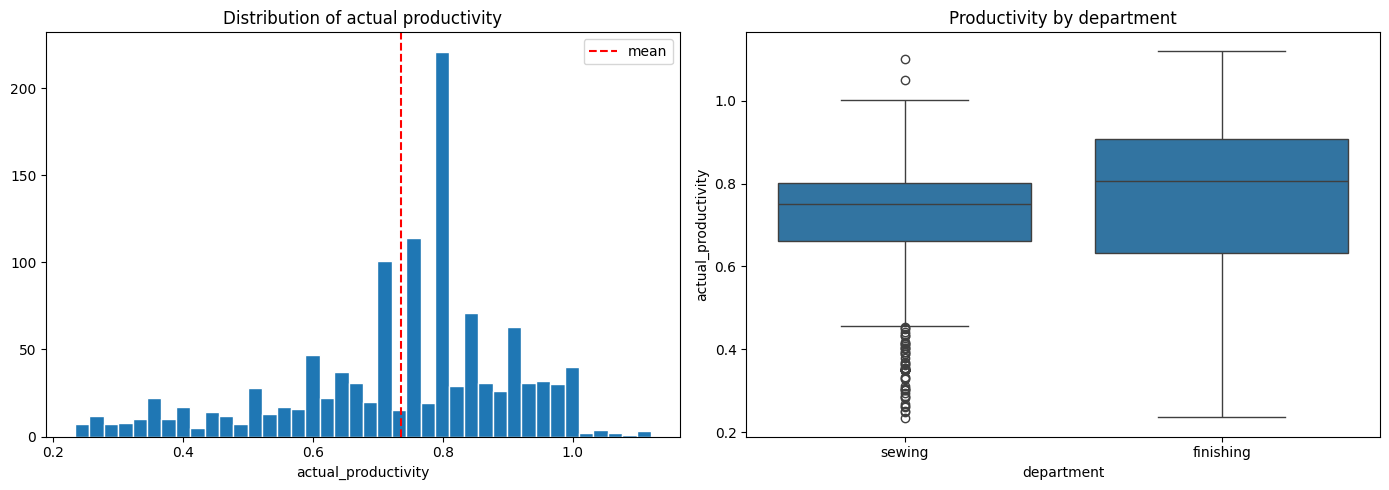

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(prod["actual_productivity"], bins=40, edgecolor="white")
axes[0].axvline(prod["actual_productivity"].mean(), color="red", linestyle="--", label="mean")
axes[0].set_title("Distribution of actual productivity")
axes[0].set_xlabel("actual_productivity")
axes[0].legend()

sns.boxplot(data=prod, x="department", y="actual_productivity", ax=axes[1])
axes[1].set_title("Productivity by department")

plt.tight_layout()
plt.show()

The target is left-skewed and clips around 1.0, with a tail of under-performing days. Note that `actual_productivity` exceeds 1.0 for some records — teams can beat their target.

In [26]:
# Did teams hit the target they were set?
prod["hit_target"] = prod["actual_productivity"] >= prod["targeted_productivity"]
print(prod["hit_target"].value_counts(normalize=True).round(3))

print("\nHit rate by department:")
print(prod.groupby("department")["hit_target"].mean().round(3))

hit_target
True     0.731
False    0.269
Name: proportion, dtype: float64

Hit rate by department:
department
finishing    0.597
sewing       0.829
Name: hit_target, dtype: float64


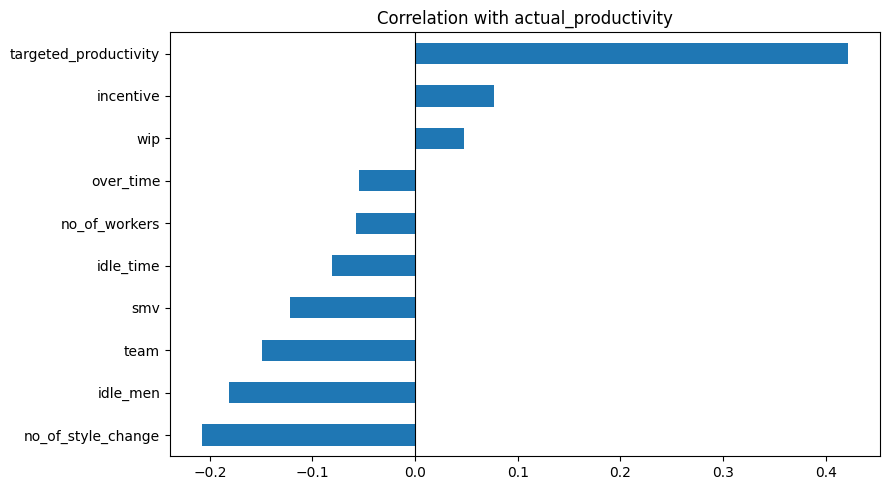

no_of_style_change      -0.207366
idle_men                -0.181734
team                    -0.148753
smv                     -0.122089
idle_time               -0.080851
no_of_workers           -0.057991
over_time               -0.054206
wip                      0.047389
incentive                0.076538
targeted_productivity    0.421594
Name: actual_productivity, dtype: float64

In [27]:
numeric = prod.select_dtypes(include=[np.number])
corr = numeric.corr()["actual_productivity"].drop("actual_productivity").sort_values()

plt.figure(figsize=(9, 5))
corr.plot(kind="barh")
plt.title("Correlation with actual_productivity")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

corr

`targeted_productivity` and `incentive` are the strongest positive signals; `smv` (standard minute value, i.e. task complexity) and `no_of_workers` pull the other way. That already hints at the story: simpler tasks with motivated, incentivised teams do best.

## Feature engineering

The date column is more useful decomposed, and the categoricals need encoding before a tree can split on them.

In [28]:
model_df = prod.drop(columns=["hit_target"]).copy()

# Break the date into usable components
model_df["date"] = pd.to_datetime(model_df["date"])
model_df["month"] = model_df["date"].dt.month
model_df["day_of_month"] = model_df["date"].dt.day
model_df = model_df.drop(columns=["date"])

# One-hot encode the remaining categoricals
cat_cols = ["quarter", "department", "day"]
model_df = pd.get_dummies(model_df, columns=cat_cols, drop_first=True)

print(model_df.shape)
model_df.head()

(1197, 23)


,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity,month,day_of_month,quarter_Quarter2,quarter_Quarter3,quarter_Quarter4,quarter_Quarter5,department_sewing,day_Saturday,day_Sunday,day_Thursday,day_Tuesday,day_Wednesday
0,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725,1,1,False,False,False,False,True,False,False,True,False,False
1,1,0.75,3.94,0.0,960,0,0.0,0,0,8.0,0.886500,1,1,False,False,False,False,False,False,False,True,False,False
2,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570,1,1,False,False,False,False,True,False,False,True,False,False
3,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570,1,1,False,False,False,False,True,False,False,True,False,False
4,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382,1,1,False,False,False,False,True,False,False,True,False,False


In [29]:
X = model_df.drop(columns=["actual_productivity"])
y = model_df["actual_productivity"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (957, 22)  Test: (240, 22)


## Baseline

Before any model, what does predicting the mean get us? Every model has to beat this to be worth anything.

In [30]:
baseline_pred = np.full(len(y_test), y_train.mean())
print("Baseline RMSE:", round(np.sqrt(mean_squared_error(y_test, baseline_pred)), 4))
print("Baseline MAE :", round(mean_absolute_error(y_test, baseline_pred), 4))
print("Baseline R^2 :", round(r2_score(y_test, baseline_pred), 4))

Baseline RMSE: 0.1635
Baseline MAE : 0.1274
Baseline R^2 : -0.0064


## Decision tree regressor

In [31]:
tree = DecisionTreeRegressor(random_state=42)
tree.fit(X_train, y_train)

tree_pred = tree.predict(X_test)
print("Unpruned tree")
print("  RMSE:", round(np.sqrt(mean_squared_error(y_test, tree_pred)), 4))
print("  R^2 :", round(r2_score(y_test, tree_pred), 4))
print("  Train R^2:", round(tree.score(X_train, y_train), 4), "<- memorised the training set")

Unpruned tree
  RMSE: 0.1509
  R^2 : 0.1419
  Train R^2: 1.0 <- memorised the training set


A train R² near 1.0 against a much lower test R² is textbook overfitting — the unpruned tree grew until every leaf was pure. Let's tune the depth and leaf constraints.

In [32]:
param_grid = {
    "max_depth": [3, 5, 7, 10, 15, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 5, 10, 20],
}

tree_search = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    param_grid,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
)
tree_search.fit(X_train, y_train)

print("Best params:", tree_search.best_params_)
print("Best CV RMSE:", round(np.sqrt(-tree_search.best_score_), 4))

Best params: {'max_depth': 7, 'min_samples_leaf': 10, 'min_samples_split': 2}
Best CV RMSE: 0.1427


In [33]:
best_tree = tree_search.best_estimator_
tuned_pred = best_tree.predict(X_test)

print("Tuned tree")
print("  RMSE:", round(np.sqrt(mean_squared_error(y_test, tuned_pred)), 4))
print("  MAE :", round(mean_absolute_error(y_test, tuned_pred), 4))
print("  R^2 :", round(r2_score(y_test, tuned_pred), 4))
print("  Train R^2:", round(best_tree.score(X_train, y_train), 4))

Tuned tree
  RMSE: 0.1335
  MAE : 0.0844
  R^2 : 0.3287
  Train R^2: 0.5648


## Random forest

A single tuned tree is still a high-variance estimator. Averaging many decorrelated trees should do better.

In [34]:
rf_grid = {
    "n_estimators": [100, 300],
    "max_depth": [10, 20, None],
    "min_samples_leaf": [1, 2, 5],
    "max_features": ["sqrt", 1.0],
}

rf_search = GridSearchCV(
    RandomForestRegressor(random_state=42),
    rf_grid,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
)
rf_search.fit(X_train, y_train)

print("Best params:", rf_search.best_params_)
print("Best CV RMSE:", round(np.sqrt(-rf_search.best_score_), 4))

Best params: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 300}
Best CV RMSE: 0.1254


In [35]:
best_rf = rf_search.best_estimator_
rf_pred = best_rf.predict(X_test)

print("Tuned random forest")
print("  RMSE:", round(np.sqrt(mean_squared_error(y_test, rf_pred)), 4))
print("  MAE :", round(mean_absolute_error(y_test, rf_pred), 4))
print("  R^2 :", round(r2_score(y_test, rf_pred), 4))

Tuned random forest
  RMSE: 0.1148
  MAE : 0.0775
  R^2 : 0.5033


## Model comparison

In [36]:
results = pd.DataFrame({
    "model": ["Baseline (mean)", "Unpruned tree", "Tuned tree", "Tuned random forest"],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_pred)),
        np.sqrt(mean_squared_error(y_test, tree_pred)),
        np.sqrt(mean_squared_error(y_test, tuned_pred)),
        np.sqrt(mean_squared_error(y_test, rf_pred)),
    ],
    "MAE": [
        mean_absolute_error(y_test, baseline_pred),
        mean_absolute_error(y_test, tree_pred),
        mean_absolute_error(y_test, tuned_pred),
        mean_absolute_error(y_test, rf_pred),
    ],
    "R2": [
        r2_score(y_test, baseline_pred),
        r2_score(y_test, tree_pred),
        r2_score(y_test, tuned_pred),
        r2_score(y_test, rf_pred),
    ],
}).round(4)

results.sort_values("RMSE")

,model,RMSE,MAE,R2
3,Tuned random forest,0.1148,0.0775,0.5033
2,Tuned tree,0.1335,0.0844,0.3287
1,Unpruned tree,0.1509,0.0862,0.1419
0,Baseline (mean),0.1635,0.1274,-0.0064


## What actually drives productivity

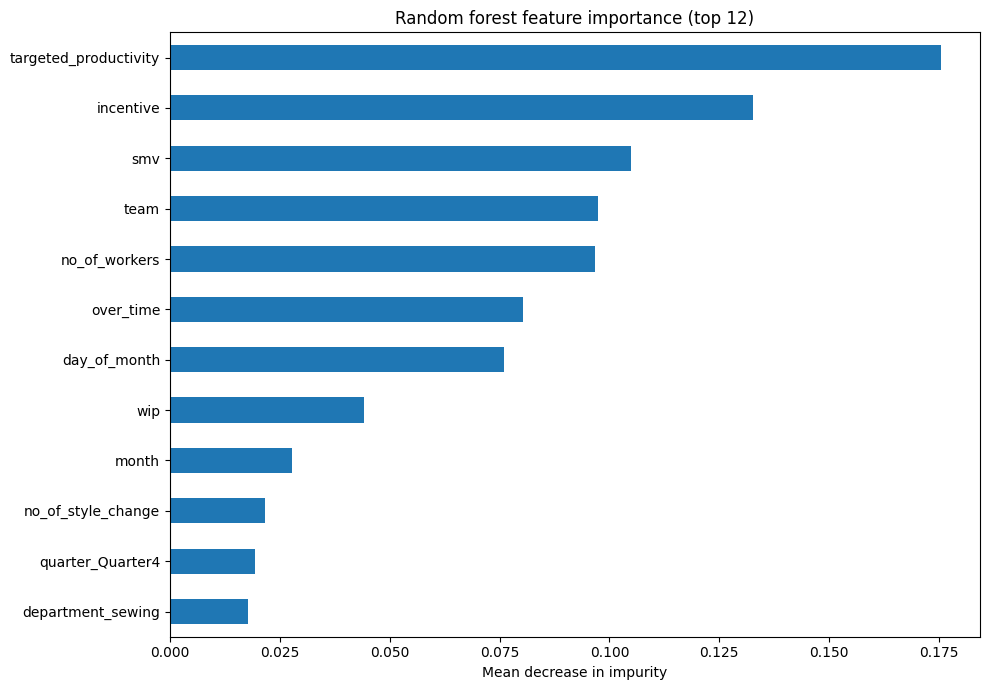

targeted_productivity    0.175564
incentive                0.132573
smv                      0.105028
team                     0.097389
no_of_workers            0.096794
over_time                0.080396
day_of_month             0.075977
wip                      0.044105
month                    0.027669
no_of_style_change       0.021545
dtype: float64

In [37]:
importances = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 7))
importances.head(12).sort_values().plot(kind="barh")
plt.title("Random forest feature importance (top 12)")
plt.xlabel("Mean decrease in impurity")
plt.tight_layout()
plt.show()

importances.head(10)

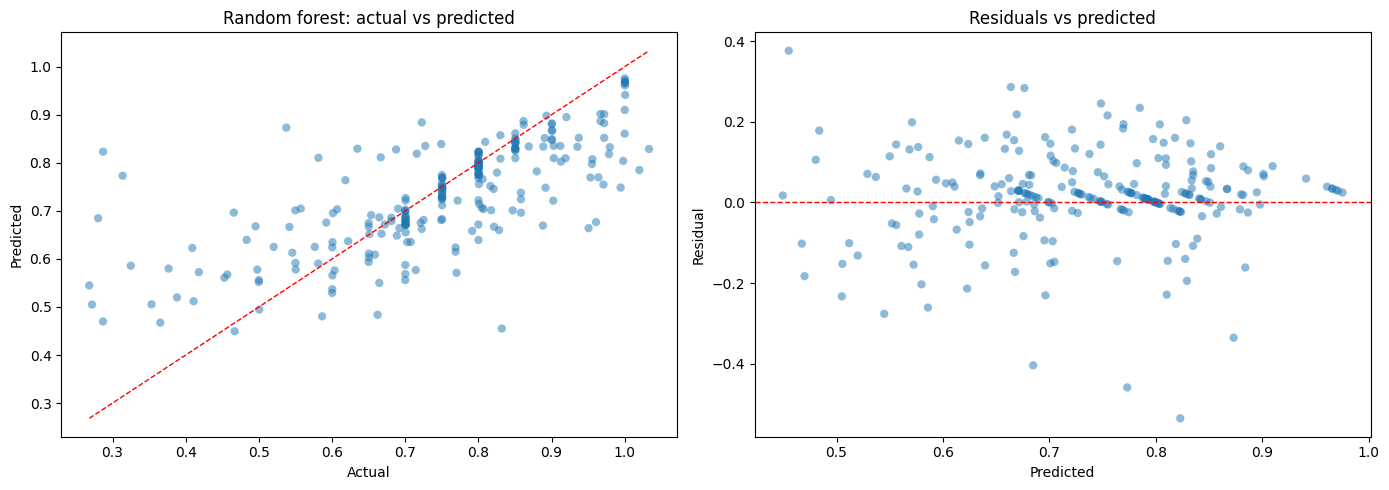

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, rf_pred, alpha=0.5, edgecolor="none")
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, "r--", linewidth=1)
axes[0].set_xlabel("Actual")
axes[0].set_ylabel("Predicted")
axes[0].set_title("Random forest: actual vs predicted")

residuals = y_test - rf_pred
axes[1].scatter(rf_pred, residuals, alpha=0.5, edgecolor="none")
axes[1].axhline(0, color="red", linestyle="--", linewidth=1)
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Residual")
axes[1].set_title("Residuals vs predicted")

plt.tight_layout()
plt.show()

## Conclusions

**Model performance.** The tuned random forest is the strongest model, beating both the mean baseline and a single decision tree on RMSE, MAE and R². The unpruned tree showed the classic failure mode — near perfect training fit, poor generalisation — which tuning `max_depth`, `min_samples_split` and `min_samples_leaf` corrected.

**What drives productivity.**

1. **`targeted_productivity`** dominates. Targets are set per team based on what that team can realistically achieve, so it encodes a lot of prior knowledge about the team.
2. **`incentive`** matters materially. Financial incentive is one of the few variables management directly controls, and it shows up high in importance — the clearest actionable lever here.
3. **`smv`** (task complexity) and **`no_of_workers`** push productivity down. Bigger teams on more complex operations under-perform, which points at coordination overhead.
4. **Idle time and style changes** are rare but damaging when they occur.

**Caveats.** Mean-decrease-in-impurity importance is biased toward high-cardinality continuous features, so the ranking above should be read as indicative rather than causal. The residual plot also shows the model struggling at the low-productivity extreme — the rare bad days are exactly the ones a factory would most want to predict, and that would be the next thing to work on (likely via a classification framing of "will this team miss target?" rather than regression).